# Correlation

This notebook accompanies [Correlation](../../notes/joint_distributions_and_covariance/correlation.md). We compute Pearson's $r$ and Spearman's $r_s$ by hand-style formulas, check them against `scipy.stats`, and look at when the two disagree.

## Pearson's $r$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 1, 4, 3, 5], dtype=float)

sxy = np.sum((x - x.mean()) * (y - y.mean()))
sxx = np.sum((x - x.mean()) ** 2)
syy = np.sum((y - y.mean()) ** 2)
r = sxy / np.sqrt(sxx * syy)
print(f"Sxy={sxy}, Sxx={sxx}, Syy={syy}, r={r:.4f}")

r_scipy, p_value = stats.pearsonr(x, y)
print("scipy pearsonr:", round(r_scipy, 4), " p-value:", round(p_value, 4))

Sxy=8.0, Sxx=10.0, Syy=10.0, r=0.8000
scipy pearsonr: 0.8  p-value: 0.1041


## Spearman's $r_s$

Without ties, $r_s=1-\frac{6\sum d_i^2}{n(n^2-1)}$ with $d_i$ the rank differences. Equivalently, it is Pearson's $r$ computed on the ranks.

In [2]:
rx, ry = stats.rankdata(x), stats.rankdata(y)
d = rx - ry
rs = 1 - 6 * np.sum(d ** 2) / (len(x) * (len(x) ** 2 - 1))
print("rank differences:", d, " sum d^2 =", np.sum(d ** 2))
print("r_s by formula:", rs)
print("Pearson on ranks:", np.corrcoef(rx, ry)[0, 1])
print("scipy spearmanr:", stats.spearmanr(x, y)[0])

rank differences: [-1.  1. -1.  1.  0.]  sum d^2 = 4.0
r_s by formula: 0.8
Pearson on ranks: 0.7999999999999999
scipy spearmanr: 0.7999999999999999


## Outliers: Pearson versus Spearman

One extreme value in an otherwise perfectly monotone relationship lowers Pearson's $r$ but not Spearman's $r_s$.

Pearson : 0.7455
Spearman: 1.0


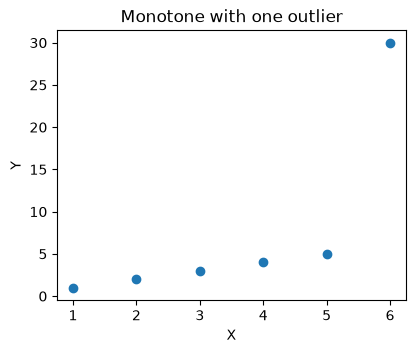

In [3]:
x2 = np.arange(1, 7, dtype=float)
y2 = np.array([1, 2, 3, 4, 5, 30], dtype=float)
print("Pearson :", round(stats.pearsonr(x2, y2)[0], 4))
print("Spearman:", round(stats.spearmanr(x2, y2)[0], 4))

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.scatter(x2, y2)
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_title("Monotone with one outlier")
plt.show()

## Non-monotone dependence

For $Y=X^2$ with $X$ symmetric about zero, both coefficients are near zero even though $Y$ is determined by $X$. A monotone but non-linear relation such as $Y=e^X$ keeps $r_s=1$ while $r<1$.

In [4]:
xs = rng.uniform(-2, 2, 2000)
print("Y = X^2   : Pearson %.3f, Spearman %.3f" % (stats.pearsonr(xs, xs**2)[0], stats.spearmanr(xs, xs**2)[0]))
print("Y = exp(X): Pearson %.3f, Spearman %.3f" % (stats.pearsonr(xs, np.exp(xs))[0], stats.spearmanr(xs, np.exp(xs))[0]))

Y = X^2   : Pearson 0.030, Spearman 0.020
Y = exp(X): Pearson 0.900, Spearman 1.000


## Invariance properties

Pearson's $r$ changes sign under a negative scaling and is otherwise invariant to linear changes of units; Spearman's $r_s$ is invariant to any increasing transformation.

In [5]:
r0 = stats.pearsonr(x, y)[0]
print("r(X,Y)           =", round(r0, 4))
print("r(2X+3, -5Y+1)   =", round(stats.pearsonr(2 * x + 3, -5 * y + 1)[0], 4))
print("rs(X, Y)         =", round(stats.spearmanr(x, y)[0], 4))
print("rs(X, exp(Y))    =", round(stats.spearmanr(x, np.exp(y))[0], 4))
print("r(X, exp(Y))     =", round(stats.pearsonr(x, np.exp(y))[0], 4), "(changes)")

r(X,Y)           = 0.8
r(2X+3, -5Y+1)   = -0.8
rs(X, Y)         = 0.8
rs(X, exp(Y))    = 0.8
r(X, exp(Y))     = 0.7837 (changes)


## Sampling variability of $r$

With only $n=10$ pairs and a true correlation of $0.5$, the sample $r$ varies a lot. Here we simulate 5,000 samples from a bivariate normal.

mean r: 0.484  sd: 0.269
central 95% range: [-0.154  0.87 ]


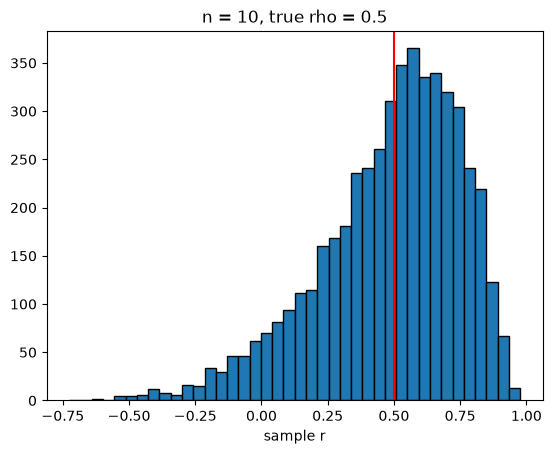

In [6]:
cov_mat = [[1, 0.5], [0.5, 1]]
rs_sim = np.array([
    np.corrcoef(rng.multivariate_normal([0, 0], cov_mat, size=10).T)[0, 1]
    for _ in range(5000)
])
print("mean r:", round(rs_sim.mean(), 3), " sd:", round(rs_sim.std(ddof=1), 3))
print("central 95% range:", np.round(np.percentile(rs_sim, [2.5, 97.5]), 3))
plt.hist(rs_sim, bins=40, edgecolor="black")
plt.axvline(0.5, color="red"); plt.xlabel("sample r"); plt.title("n = 10, true rho = 0.5")
plt.show()